* `Age` (Edad)
* `Height` (Altura)
* `Weight` (Peso)
* `FCVC` (Frecuencia de consumo de vegetales)
* `NCP` (Número de comidas principales)
* `CH2O` (Consumo diario de agua)
* `FAF` (Frecuencia de actividad física)
* `TUE` (Tiempo de uso de dispositivos tecnológicos)

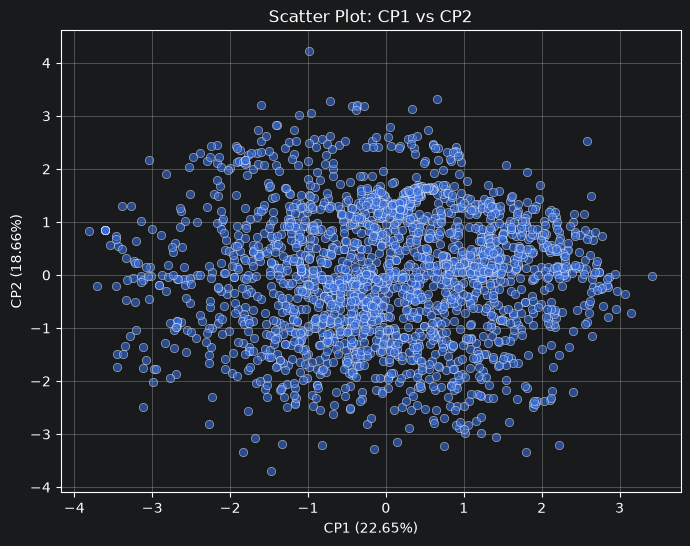

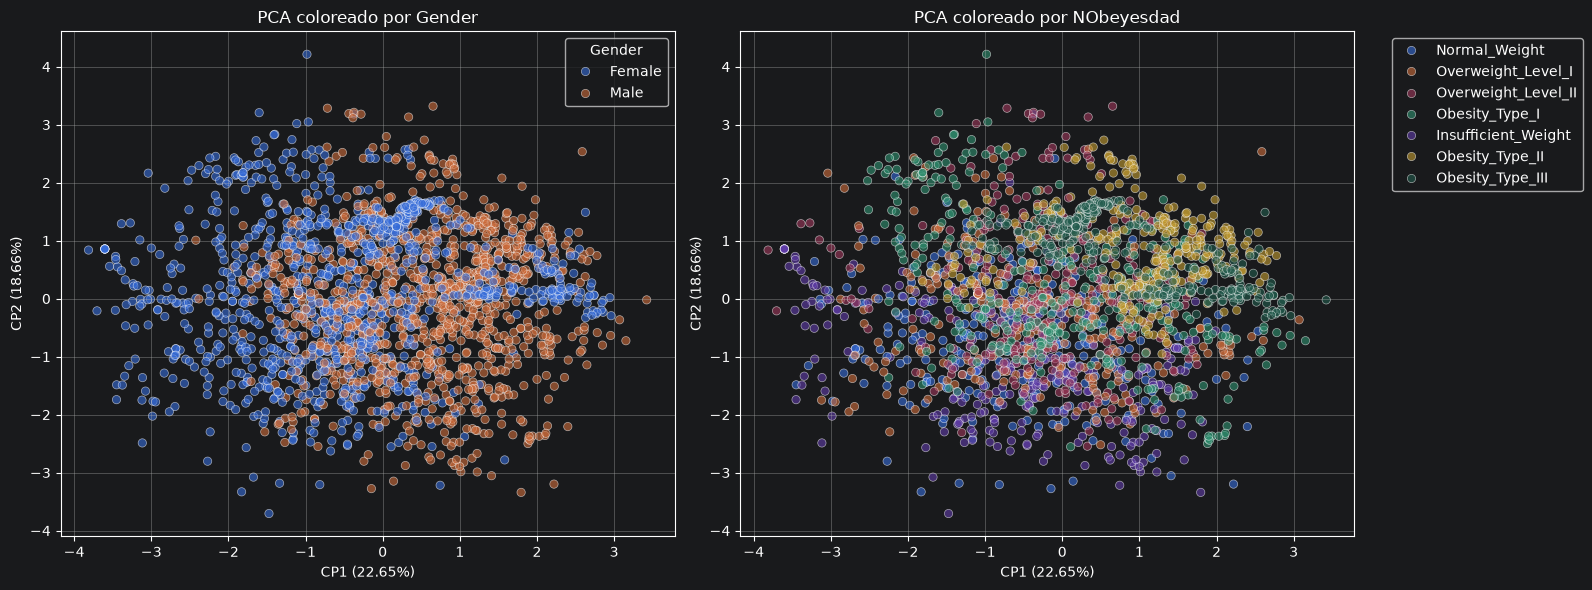

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Cargar datos
# Asegúrate de que el archivo CSV esté en la misma carpeta que tu script
df = pd.read_csv('ObesityDataSet_raw_and_data_sinthetic.csv')

# Variables numéricas y categóricas a utilizar
num_cols = ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']

# 2. Estandarización de las variables numéricas
X = df[num_cols]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Aplicar PCA (2 componentes)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Guardar la varianza explicada para las etiquetas
var_cp1 = pca.explained_variance_ratio_[0] * 100
var_cp2 = pca.explained_variance_ratio_[1] * 100 # Corregido: antes decía [2]

# 4. Crear DataFrame con las componentes y las etiquetas categóricas
df_pca = pd.DataFrame(X_pca, columns=['CP1', 'CP2'])
df_pca['Gender'] = df['Gender']
df_pca['NObeyesdad'] = df['NObeyesdad']

# ==========================================
# GRÁFICO 1: Scatter Plot Simple
# ==========================================
plt.figure(figsize=(8, 6))
sns.scatterplot(x='CP1', y='CP2', data=df_pca, alpha=0.6)
plt.title('Scatter Plot: CP1 vs CP2')
plt.xlabel(f'CP1 ({var_cp1:.2f}%)')
plt.ylabel(f'CP2 ({var_cp2:.2f}%)')
plt.grid(True)
plt.show()

# ==========================================
# GRÁFICO 2: Scatter coloreado por Categorías
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Por Género
sns.scatterplot(x='CP1', y='CP2', hue='Gender', data=df_pca, alpha=0.6, ax=axes[0])
axes[0].set_title('PCA coloreado por Gender')
axes[0].set_xlabel(f'CP1 ({var_cp1:.2f}%)')
axes[0].set_ylabel(f'CP2 ({var_cp2:.2f}%)')
axes[0].grid(True)

# Por Nivel de Obesidad
sns.scatterplot(x='CP1', y='CP2', hue='NObeyesdad', data=df_pca, alpha=0.6, ax=axes[1])
axes[1].set_title('PCA coloreado por NObeyesdad')
axes[1].set_xlabel(f'CP1 ({var_cp1:.2f}%)')
axes[1].set_ylabel(f'CP2 ({var_cp2:.2f}%)')
axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left') # Mueve la leyenda fuera del gráfico
axes[1].grid(True)

plt.tight_layout()
plt.show()

# ==========================================
#


**Resultados numéricos:**
* **Ratio de varianza CP1:** **22.65%**
* **Ratio de varianza CP2:** **18.66%**
* **Varianza acumulada total (CP1 + CP2):** **41.31%**

**No alcanzando una representatividad óptima.** Conjuntamente, CP1 y CP2 capturan únicamente el **41.31%** de la varianza total de los datos. Esto implica que más del **58.6%** de la información original se pierde al proyectar el dataset en solo 2 dimensiones. Cuando las variables cuantitativas presentan relaciones complejas y no altamente correlacionadas entre sí, dos dimensiones lineales resultan insuficientes para resumir adecuadamente la estructura del espacio multidimensional

* C)
**No de forma completa.** Debido a que PCA efectúa proyecciones estrictamente lineales[3], no logra separar adecuadamente clases complejas en espacios proyectados de baja varianza explicada. Para lograr una visualización que separe mejor los grupos agrupados por proximidad local, se suelen requerir algoritmos no lineales de *manifold learning* como **t-SNE** o **UMAP**

### D)
* **Componente Principal 1 (CP1 - 22.65%):**
* Está dominada de forma positiva por **Height** **(0.60)**, **Weight** **(0.50)**, **CH2O** **(0.38)**, **NCP** **(0.33)** y **FAF** **(0.32)**.
* **Interpretación:** Representa un eje de **dimensión física y hábitos de volumen corporal/actividad**. Valores altos en CP1 corresponden a personas con mayor estatura, peso, consumo de agua/comidas y actividad física.
* **Componente Principal 2 (CP2 - 18.66%):**
* Presenta mayor peso positivo en **Age** **(0.60)** y **Weight** **(0.36)**, y peso negativo significativo en **TUE** **(-0.53)** y **FAF** **(-0.36)**.
* **Interpretación:** Contrapone la **edad frente al estilo de vida digital y actividad física**. Muestra que a mayor edad se tiende a registrar menor tiempo de uso de tecnología (`TUE`) y menor frecuencia de actividad física (`FAF`).

In [3]:
# ==========================================
# INFLUENCIA DE LAS VARIABLES (Loadings)
# ==========================================
# Creamos un DataFrame con los pesos de cada variable original en las componentes
loadings = pd.DataFrame(
    pca.components_.T,      # Transponemos la matriz de componentes
    columns=['CP1', 'CP2'], # Nombres de las componentes
    index=num_cols          # Nombres de las variables originales
)

print("--- Influencia de las variables en cada dimensión (Pesos/Loadings) ---")
print(loadings.round(2)) # Redondeamos a 2 decimales para leerlo más fácil

--- Influencia de las variables en cada dimensión (Pesos/Loadings) ---
         CP1   CP2
Age     0.01  0.60
Height  0.60 -0.07
Weight  0.50  0.36
FCVC    0.16  0.26
NCP     0.33 -0.13
CH2O    0.38 -0.05
FAF     0.32 -0.36
TUE     0.01 -0.53
